In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import shap
import joblib, os

In [11]:
df = pd.read_csv("city_day.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y", errors="coerce")
print("Bad dates:", df["Date"].isna().sum())   # should be 0

cov = df.groupby("City").agg(
    rows=("Date", "count"),
    start=("Date", "min"),
    end=("Date", "max"),
    pm25_ok=("PM2.5", lambda s: s.notna().mean()),
    pm10_ok=("PM10", lambda s: s.notna().mean()),
    aqi_ok=("AQI", lambda s: s.notna().mean()),
).sort_values("aqi_ok", ascending=False)
print(cov.round(2))

Bad dates: 29531
                    rows start end  pm25_ok  pm10_ok  aqi_ok
City                                                        
Delhi                  0   NaT NaT     1.00     0.96    1.00
Guwahati               0   NaT NaT     1.00     1.00    0.99
Chandigarh             0   NaT NaT     0.95     1.00    0.98
Aizawl                 0   NaT NaT     0.98     0.99    0.98
Jaipur                 0   NaT NaT     0.99     0.99    0.98
Kochi                  0   NaT NaT     1.00     1.00    0.98
Bhopal                 0   NaT NaT     0.97     0.97    0.96
Bengaluru              0   NaT NaT     0.93     0.82    0.95
Thiruvananthapuram     0   NaT NaT     0.96     0.97    0.95
Ernakulam              0   NaT NaT     0.98     0.98    0.94
Lucknow                0   NaT NaT     0.95     0.00    0.94
Chennai                0   NaT NaT     0.94     0.15    0.94
Hyderabad              0   NaT NaT     0.94     0.82    0.94
Kolkata                0   NaT NaT     0.93     0.93    0.93
Amritsa

C:\Users\Rohan\AppData\Local\Temp\ipykernel_4492\4080163321.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(cov.round(2))


In [12]:
import pandas as pd, numpy as np

df = pd.read_csv("city_day.csv")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")   # no format= here
print("Bad dates:", df["Date"].isna().sum())               # must be 0
print(df["Date"].min(), df["Date"].max())                  # 2015-01-01 ... 2020-07-01

Bad dates: 0
2015-01-01 00:00:00 2020-07-01 00:00:00


In [13]:
CITIES = ["Delhi", "Jaipur", "Kolkata", "Bengaluru", "Hyderabad"]
POLL = ["PM2.5","PM10","NO","NO2","NOx","NH3","CO","SO2","O3"]

d = df[df["City"].isin(CITIES)].drop(columns=["Benzene","Toluene","Xylene","AQI_Bucket"])
d = d.sort_values(["City","Date"])

out = []
for city, g in d.groupby("City"):
    g = g.set_index("Date").asfreq("D")
    g["City"] = city
    g[POLL + ["AQI"]] = g[POLL + ["AQI"]].interpolate(limit=3)
    out.append(g.reset_index())
d = pd.concat(out)

d["AQI"] = d["AQI"].clip(upper=500)
d = d.dropna(subset=["AQI","PM2.5"]).reset_index(drop=True)

print(d.groupby("City").agg(rows=("Date","count"), start=("Date","min"), end=("Date","max")))
print(d.isna().sum())

           rows      start        end
City                                 
Bengaluru  1895 2015-03-21 2020-07-01
Delhi      2008 2015-01-01 2020-07-01
Hyderabad  1901 2015-03-31 2020-07-01
Jaipur     1106 2017-06-20 2020-07-01
Kolkata     757 2018-04-11 2020-07-01
Date       0
City       0
PM2.5      0
PM10     541
NO         0
NO2        0
NOx      104
NH3      357
CO         0
SO2      109
O3       143
AQI        0
dtype: int64


EDA

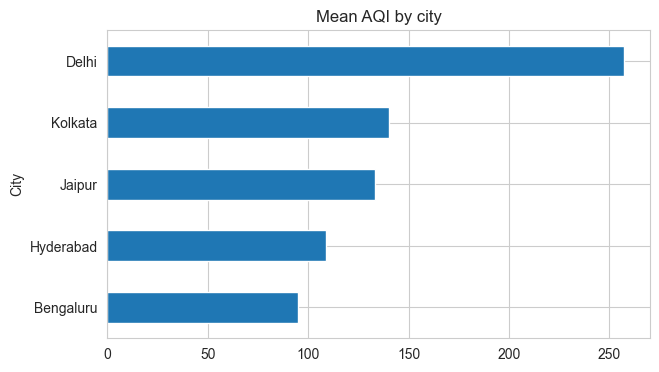

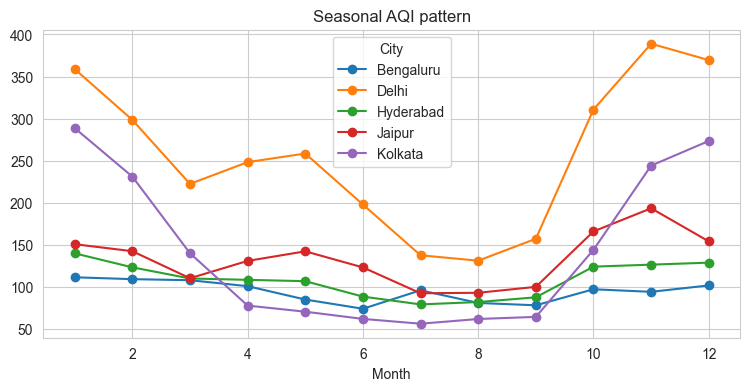

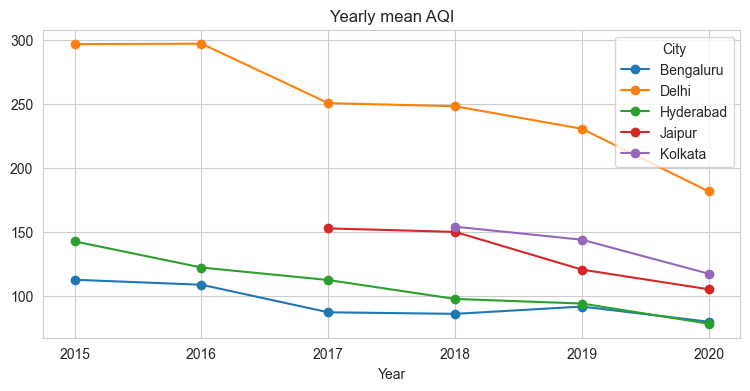

            2019  2020 (lockdown)  change_%
City                                       
Bengaluru  102.2             65.8     -35.6
Delhi      217.0            125.5     -42.2
Hyderabad   93.1             64.2     -31.0
Jaipur     136.5             95.7     -29.9
Kolkata     87.0             59.9     -31.2


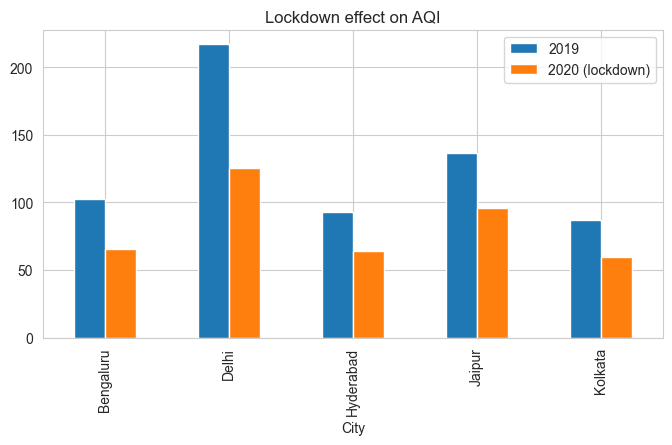

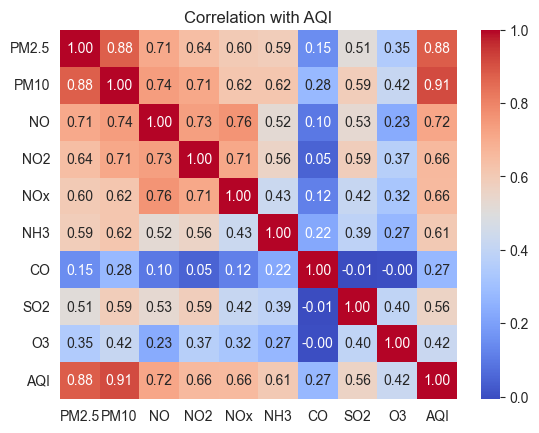

In [14]:
sns.set_style("whitegrid")

d["Year"] = d["Date"].dt.year
d["Month"] = d["Date"].dt.month

# 1. City comparison (mean AQI)
d.groupby("City")["AQI"].mean().sort_values().plot(kind="barh", figsize=(7,4), title="Mean AQI by city")
plt.show()

# 2. Seasonality: mean AQI by month, per city
pivot = d.pivot_table(index="Month", columns="City", values="AQI", aggfunc="mean")
pivot.plot(figsize=(9,4), marker="o", title="Seasonal AQI pattern")
plt.show()

# 3. Yearly trend
d.pivot_table(index="Year", columns="City", values="AQI", aggfunc="mean").plot(
    figsize=(9,4), marker="o", title="Yearly mean AQI")
plt.show()

# 4. Lockdown vs same period in 2019 (Mar 25 - Jun 30)
def window(y):
    return d[(d["Date"] >= f"{y}-03-25") & (d["Date"] <= f"{y}-06-30")]
cmp = pd.DataFrame({
    "2019": window(2019).groupby("City")["AQI"].mean(),
    "2020 (lockdown)": window(2020).groupby("City")["AQI"].mean(),
})
cmp["change_%"] = ((cmp["2020 (lockdown)"] - cmp["2019"]) / cmp["2019"] * 100).round(1)
print(cmp.round(1))
cmp[["2019","2020 (lockdown)"]].plot(kind="bar", figsize=(8,4), title="Lockdown effect on AQI")
plt.show()

# 5. Which pollutants move with AQI
sns.heatmap(d[POLL + ["AQI"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation with AQI")
plt.show()

FEATURE SELECTION

In [15]:
f = d.sort_values(["City","Date"]).reset_index(drop=True).copy()
g = f.groupby("City")

# lag / rolling features (all use only past info)
for l in [1,2,3,7,14]:
    f[f"AQI_lag{l}"] = g["AQI"].shift(l)
f["PM25_lag1"] = g["PM2.5"].shift(1)
for w in [7,30]:
    f[f"AQI_roll{w}"] = g["AQI"].transform(lambda s: s.shift(1).rolling(w, min_periods=3).mean())

# calendar features
f["dow"] = f["Date"].dt.dayofweek
f["doy_sin"] = np.sin(2*np.pi*f["Date"].dt.dayofyear/365)
f["doy_cos"] = np.cos(2*np.pi*f["Date"].dt.dayofyear/365)
f["city_code"] = f["City"].astype("category").cat.codes

FEATS = POLL + ["AQI","PM25_lag1","AQI_lag1","AQI_lag2","AQI_lag3","AQI_lag7","AQI_lag14",
                "AQI_roll7","AQI_roll30","Month","dow","doy_sin","doy_cos","city_code"]

# targets: AQI h days ahead
for h in range(1, 8):
    f[f"y_h{h}"] = f.groupby("City")["AQI"].shift(-h)

def split(h):
    t = f.dropna(subset=[f"y_h{h}","AQI_lag14","AQI_roll30"])
    train = t[t["Date"] <= "2019-12-31"]
    pre   = t[(t["Date"] >= "2020-01-01") & (t["Date"] <= "2020-03-24")]
    lock  = t[t["Date"] >= "2020-03-25"]
    return train, pre, lock

def metrics(y, p):
    return dict(MAE=mean_absolute_error(y,p),
                RMSE=mean_squared_error(y,p)**0.5,
                R2=r2_score(y,p))

rows = []
for h in [1, 3, 7]:
    train, pre, lock = split(h)
    tgt = f"y_h{h}"
    model = xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                             subsample=0.8, colsample_bytree=0.8, random_state=42)
    model.fit(train[FEATS], train[tgt])
    for name, part in [("pre-lockdown", pre), ("lockdown", lock)]:
        base = metrics(part[tgt], part["AQI"])                      # persistence baseline
        xgbm = metrics(part[tgt], model.predict(part[FEATS]))
        rows.append({"horizon": h, "period": name, "model": "Persistence", **base})
        rows.append({"horizon": h, "period": name, "model": "XGBoost", **xgbm})

res = pd.DataFrame(rows).round(2)
print(res.sort_values(["horizon","period","model"]).to_string(index=False))

 horizon       period       model   MAE  RMSE   R2
       1     lockdown Persistence 10.40 15.96 0.79
       1     lockdown     XGBoost  9.28 13.26 0.85
       1 pre-lockdown Persistence 22.47 33.12 0.81
       1 pre-lockdown     XGBoost 15.85 22.66 0.91
       3     lockdown Persistence 15.71 23.38 0.55
       3     lockdown     XGBoost 15.86 22.81 0.57
       3 pre-lockdown Persistence 38.81 56.41 0.42
       3 pre-lockdown     XGBoost 32.13 45.42 0.62
       7     lockdown Persistence 18.64 26.74 0.43
       7     lockdown     XGBoost 19.56 27.07 0.41
       7 pre-lockdown Persistence 38.04 52.53 0.47
       7 pre-lockdown     XGBoost 35.40 46.30 0.59


 horizon       period       model   MAE  RMSE   R2
       1     lockdown Persistence 10.40 15.96 0.79
       1     lockdown   XGB-delta  9.36 13.41 0.85
       1 pre-lockdown Persistence 22.47 33.12 0.81
       1 pre-lockdown   XGB-delta 17.45 25.03 0.89
       3     lockdown Persistence 15.71 23.38 0.55
       3     lockdown   XGB-delta 15.24 21.85 0.60
       3 pre-lockdown Persistence 38.81 56.41 0.42
       3 pre-lockdown   XGB-delta 32.88 45.48 0.62
       7     lockdown Persistence 18.64 26.74 0.43
       7     lockdown   XGB-delta 18.41 25.11 0.50
       7 pre-lockdown Persistence 38.04 52.53 0.47
       7 pre-lockdown   XGB-delta 33.71 44.45 0.62
 horizon      City  n  MAE_xgb  MAE_persist
       1 Bengaluru 84      8.6          9.6
       1     Delhi 84     30.8         41.5
       1 Hyderabad 84      9.9         11.4
       1    Jaipur 84     12.0         14.2
       1   Kolkata 84     26.1         35.7
       3 Bengaluru 84     15.5         17.7
       3     Delhi 84     60.

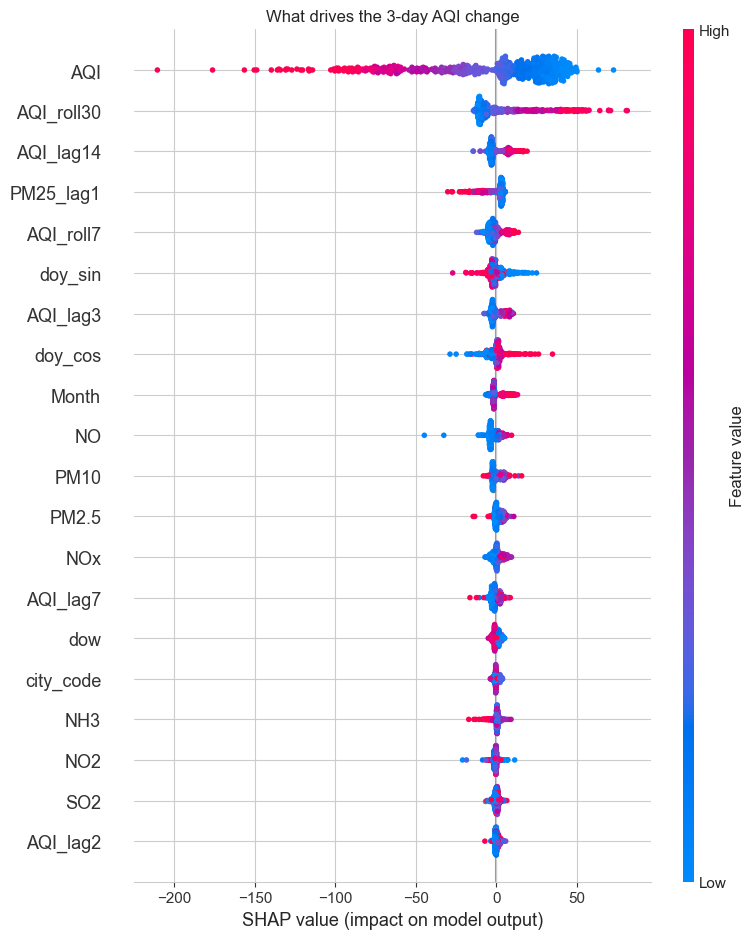

In [16]:
models, rows = {}, []
for h in [1, 3, 7]:
    train, pre, lock = split(h)
    tgt = f"y_h{h}"
    m = xgb.XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=4,
                         min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
                         random_state=42)
    m.fit(train[FEATS], train[tgt] - train["AQI"])      # predict the change
    models[h] = m
    for name, part in [("pre-lockdown", pre), ("lockdown", lock)]:
        pred = m.predict(part[FEATS]) + part["AQI"]
        rows.append({"horizon": h, "period": name, "model": "XGB-delta",
                     **metrics(part[tgt], pred)})
        rows.append({"horizon": h, "period": name, "model": "Persistence",
                     **metrics(part[tgt], part["AQI"])})
print(pd.DataFrame(rows).round(2).sort_values(["horizon","period","model"]).to_string(index=False))

# per-city metrics, pre-lockdown test window
city_rows = []
for h in [1, 3, 7]:
    _, pre, _ = split(h)
    tgt = f"y_h{h}"
    pre = pre.assign(pred=models[h].predict(pre[FEATS]) + pre["AQI"])
    for city, p in pre.groupby("City"):
        city_rows.append({"horizon": h, "City": city, "n": len(p),
                          "MAE_xgb": mean_absolute_error(p[tgt], p["pred"]),
                          "MAE_persist": mean_absolute_error(p[tgt], p["AQI"])})
print(pd.DataFrame(city_rows).round(1).to_string(index=False))

# SHAP on the 3-day model
train3, _, _ = split(3)
sample = train3[FEATS].sample(600, random_state=42)
sv = shap.TreeExplainer(models[3]).shap_values(sample)
shap.summary_plot(sv, sample, show=False)
plt.title("What drives the 3-day AQI change"); plt.tight_layout(); plt.savefig(
    r"C:\Users\Rohan\Desktop\SHAP_3day_AQI.png",
    dpi=300,
    bbox_inches="tight"
); plt.show()

SAVE THE MODELS

In [17]:
os.makedirs("artifacts", exist_ok=True)

def make_model():
    return xgb.XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=4,
                            min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
                            random_state=42)

final, holdout = {}, {}
for h in range(1, 8):
    t = f.dropna(subset=[f"y_h{h}", "AQI_lag14", "AQI_roll30"])
    m = make_model(); m.fit(t[FEATS], t[f"y_h{h}"] - t["AQI"]); final[h] = m
    th = t[t["Date"] <= "2019-12-24"]
    m2 = make_model(); m2.fit(th[FEATS], th[f"y_h{h}"] - th["AQI"]); holdout[h] = m2

joblib.dump({"models": final, "holdout": holdout, "feats": FEATS}, "artifacts/aqi_models.joblib")

f[["City", "Date"] + FEATS].to_csv("artifacts/features.csv", index=False)
f[["City","Date","AQI","PM2.5","PM10","NO2","SO2","CO","O3"]].to_csv("artifacts/history.csv", index=False)
print("saved", f.shape)
print(os.listdir("artifacts"))

saved (7667, 33)
['aqi_models.joblib', 'features.csv', 'history.csv', 'latest.csv']


In [20]:
import os; print(os.getcwd())

d:\Placements 2026\ProjectsAndMaterials\DataScience\projects\self\final_year_project\aqi-forecast
